<a href="https://colab.research.google.com/github/vcasadei/Redes-Neurais-CESAR-School/blob/2026.01-A/2%20-%20Regress%C3%A3o%20Linear/2.2_regressao_linear_numpy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 2.2 — Regressão Linear com NumPy

## Objetivos

- Estimar o comprimento das pétalas da íris a partir do comprimento das sépalas com regressão linear.
- Implementar tudo em NumPy, de forma explícita: o modelo (uma classe com uma camada), a predição, a função de custo (loss), o cálculo do gradiente e a atualização dos parâmetros.
- Escrever a predição de várias amostras de uma vez na forma matricial e acompanhar os shapes.
- Comparar o resultado do gradiente descendente com a solução analítica.

É o mesmo problema do notebook 2.1, agora sem caixas-pretas: cada passo do diagrama abaixo vira uma linha de código.

![Otimização](https://raw.githubusercontent.com/vcasadei/images/master/RegressaoLinear_Otimizacao.png)

No diagrama, $N$ é o número de amostras, que neste notebook chamamos de $M$.

## Importação das bibliotecas

In [ ]:
import matplotlib.pyplot as plt          # gráficos
import numpy as np                       # processamento matricial
from sklearn.datasets import load_iris  # para carregar o dataset

np.random.seed(1234)

## Dados

### Leitura dos dados

In [ ]:
iris = load_iris()
data = iris.data[iris.target == 1, ::2]  # versicolor; colunas 0 e 2: comprimento das sépalas e das pétalas

x_train = data[:, 0:1]
y_train = data[:, 1:2]

n_samples = x_train.shape[0]
print('x_train.shape:', x_train.shape, x_train.dtype)
print('y_train.shape:', y_train.shape, y_train.dtype)

print('x_train[:5]:\n', x_train[:5])
print('y_train[:5]:\n', y_train[:5])

x_train.shape: (50, 1) float64
y_train.shape: (50, 1) float64
x_train[:5]:
 [[7. ]
 [6.4]
 [6.9]
 [5.5]
 [6.5]]
y_train[:5]:
 [[4.7]
 [4.5]
 [4.9]
 [4. ]
 [4.6]]


### Normalização dos dados

Normalização min-max para o intervalo $[0, 1]$: $x \leftarrow \dfrac{x - \min(x)}{\max(x) - \min(x)}$, e o mesmo para $y$.

In [ ]:
x_train -= x_train.min()
x_train /= x_train.max()   # após subtrair o mínimo, o máximo vale max - min
y_train -= y_train.min()
y_train /= y_train.max()

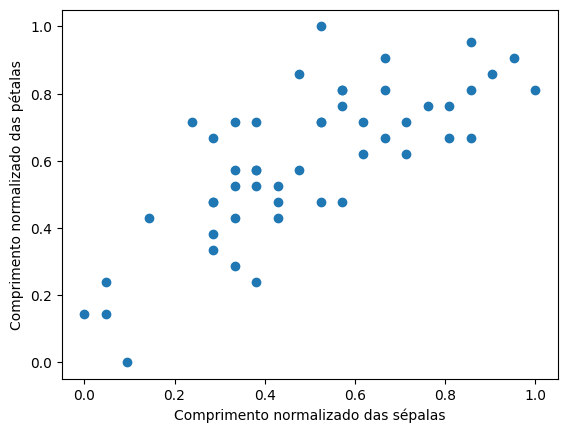

In [ ]:
plt.scatter(x_train, y_train)
plt.xlabel('Comprimento normalizado das sépalas')
plt.ylabel('Comprimento normalizado das pétalas')
plt.show()

## Modelo

### Reta de ajuste

A equação da reta no plano precisa de dois parâmetros: a interseção $w_0$ (*bias*) e a inclinação $w_1$.

![Reta](https://raw.githubusercontent.com/vcasadei/images/master/linhareta.png)

A reta de ajuste será dada por:

$$ \hat{y} = w_0 + w_1 x $$

onde
- $x$ é a variável de entrada (comprimento das sépalas);
- $\hat{y}$ é a predição (comprimento estimado das pétalas);
- $w_1$ é o coeficiente angular da reta (peso);
- $w_0$ é o valor de $\hat{y}$ quando $x = 0$ (interseção com o eixo vertical), chamado de *bias*.

Nos slides, a mesma reta aparece como $h_\theta(x) = \theta_0 + \theta_1 x$: $w_0 = \theta_0$ (bias), $w_1 = \theta_1$ (peso) e $\hat{y} = h_\theta(x)$.

### Modelo de regressão linear como neurônio

![Neurônio](https://raw.githubusercontent.com/vcasadei/images/master/RegressaoLinearNeuronio.png)

### Formulação matricial do neurônio

- $\mathbf{w} = [w_0 \ \ w_1]$ é o vetor linha de parâmetros, shape $(1, 2)$;
- $\mathbf{x} = [1 \ \ x_0]$ é o vetor linha de uma amostra, com o 1 do *bias*, shape $(1, 2)$. Aqui $x_0$ é o (único) atributo de entrada, o comprimento da sépala.

$$ \hat{y} = 1 \cdot w_0 + x_0 \cdot w_1 $$

$$ [\hat{y}] = [1 \ \ x_0] \begin{bmatrix} w_0 \\ w_1 \end{bmatrix} $$

$$ \hat{y} = \mathbf{x} \mathbf{w}^T $$

### Predição de várias amostras

Empilhando as $M$ amostras, uma por linha, obtemos a matriz $\mathbf{X}$ de shape $(M, 2)$. A predição de todas as amostras é um único produto de matrizes, $\hat{\mathbf{y}} = \mathbf{X} \mathbf{w}^T$:

$$
\begin{bmatrix}
\hat{y}_0 \\ \hat{y}_1 \\ \vdots \\ \hat{y}_{M-1}
\end{bmatrix}
=
\begin{bmatrix}
1 & x_0 \\ 1 & x_1 \\ \vdots & \vdots \\ 1 & x_{M-1}
\end{bmatrix}
\begin{bmatrix}
w_0 \\ w_1
\end{bmatrix}
$$

com shapes $(M, 1) = (M, 2) \times (2, 1)$. Atenção: na matriz, $x_i$ é o atributo da amostra $i$ (o índice agora numera as amostras).

### Preenchendo x com uma coluna de 1s para o bias

`np.hstack` concatena arrays lado a lado (na direção das colunas): `x_train_bias` = [coluna de 1s | `x_train`], shape $(M, 2) = (50, 2)$.

In [ ]:
x_train

array([[1.        ],
       [0.71428571],
       [0.95238095],
       [0.28571429],
       [0.76190476],
       [0.38095238],
       [0.66666667],
       [0.        ],
       [0.80952381],
       [0.14285714],
       [0.04761905],
       [0.47619048],
       [0.52380952],
       [0.57142857],
       [0.33333333],
       [0.85714286],
       [0.33333333],
       [0.42857143],
       [0.61904762],
       [0.33333333],
       [0.47619048],
       [0.57142857],
       [0.66666667],
       [0.57142857],
       [0.71428571],
       [0.80952381],
       [0.9047619 ],
       [0.85714286],
       [0.52380952],
       [0.38095238],
       [0.28571429],
       [0.28571429],
       [0.42857143],
       [0.52380952],
       [0.23809524],
       [0.52380952],
       [0.85714286],
       [0.66666667],
       [0.33333333],
       [0.28571429],
       [0.28571429],
       [0.57142857],
       [0.42857143],
       [0.04761905],
       [0.33333333],
       [0.38095238],
       [0.38095238],
       [0.619

In [ ]:
y_train

array([[0.80952381],
       [0.71428571],
       [0.9047619 ],
       [0.47619048],
       [0.76190476],
       [0.71428571],
       [0.80952381],
       [0.14285714],
       [0.76190476],
       [0.42857143],
       [0.23809524],
       [0.57142857],
       [0.47619048],
       [0.80952381],
       [0.28571429],
       [0.66666667],
       [0.71428571],
       [0.52380952],
       [0.71428571],
       [0.42857143],
       [0.85714286],
       [0.47619048],
       [0.9047619 ],
       [0.80952381],
       [0.61904762],
       [0.66666667],
       [0.85714286],
       [0.95238095],
       [0.71428571],
       [0.23809524],
       [0.38095238],
       [0.33333333],
       [0.42857143],
       [1.        ],
       [0.71428571],
       [0.71428571],
       [0.80952381],
       [0.66666667],
       [0.52380952],
       [0.47619048],
       [0.66666667],
       [0.76190476],
       [0.47619048],
       [0.14285714],
       [0.57142857],
       [0.57142857],
       [0.57142857],
       [0.619

In [ ]:
np.ones(shape=(n_samples, 1))

array([[1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.]])

In [ ]:
x_train_bias = np.hstack([np.ones(shape=(n_samples, 1)), x_train])
print('x_train_bias.shape:', x_train_bias.shape)
x_train_bias[:5]

x_train_bias.shape: (50, 2)


array([[1.        , 1.        ],
       [1.        , 0.71428571],
       [1.        , 0.95238095],
       [1.        , 0.28571429],
       [1.        , 0.76190476]])

### Classe com o modelo da rede

A classe guarda os parâmetros em `self.w`, shape `(n_out, n_in)` = $(1, 2)$, iniciados com valores aleatórios pequenos. O método `forward` calcula a predição $\hat{\mathbf{y}} = \mathbf{X}\mathbf{w}^T$.

In [ ]:
np.random.uniform(-0.1, 0.1, (1, 2))

array([[-0.06169611,  0.02442175]])

In [ ]:
class Net():
    def __init__(self, n_in, n_out):
        self.w = np.random.uniform(-0.1, 0.1, (n_out, n_in))  # inicialização dos parâmetros

    def forward(self, x_bias):
        return x_bias.dot(self.w.T)   # (M, 2) x (2, 1) -> (M, 1)

### Criando a rede: instanciando o objeto `model`

In [ ]:
model = Net(2, 1)  # duas entradas (1 + x0) e uma saída y_pred
print('model.w:', model.w, 'shape:', model.w.shape)

model.w: [[-0.01245445  0.05707172]] shape: (1, 2)


### Testando a predição da rede (mesmo sem treiná-la)

In [ ]:
np.random.randn(4, 2)

array([[-0.72058873,  0.88716294],
       [ 0.85958841, -0.6365235 ],
       [ 0.01569637, -2.24268495],
       [ 1.15003572,  0.99194602]])

In [ ]:
xin = np.random.randn(4, 2)  # 4 amostras, 2 entradas (1 + x0)
ypred = model.forward(xin)
print('ypred.shape:', ypred.shape)
ypred

ypred.shape: (4, 1)


array([[-0.12722961],
       [ 0.00428165],
       [ 0.01144927],
       [-0.10473886]])

In [ ]:
ypred = model.forward(x_train_bias)
ypred[:5]

array([[0.04461726],
       [0.02831106],
       [0.04189956],
       [0.00385175],
       [0.03102876]])

## Treinamento via gradiente descendente

**Função de custo** (MSE), com $M$ amostras:

$$ J(\mathbf{w}) = \frac{1}{M} \sum_{i=0}^{M-1} (\hat{y}_i - y_i)^2 = \frac{1}{M} (\mathbf{X}\mathbf{w}^T - \mathbf{y})^T (\mathbf{X}\mathbf{w}^T - \mathbf{y}) $$

onde $\mathbf{y}$ é o vetor coluna dos valores corretos, shape $(M, 1)$.

**Gradiente.** Derivando $J$ em relação a cada parâmetro $w_j$ ($j = 0, 1$), com $\hat{y}_i = w_0 \cdot 1 + w_1 x_i$:

$$ \frac{\partial J}{\partial w_j} = \frac{2}{M} \sum_{i=0}^{M-1} (\hat{y}_i - y_i)\, X_{ij} $$

onde $X_{ij}$ é o elemento da linha $i$ e coluna $j$ de $\mathbf{X}$ ($X_{i0} = 1$ e $X_{i1} = x_i$). O fator 2 vem da derivada do quadrado. Juntando as duas derivadas parciais num vetor coluna:

$$ \nabla_{\mathbf{w}} J = \frac{2}{M}\, \mathbf{X}^T (\mathbf{X} \mathbf{w}^T - \mathbf{y}) $$

com shapes $(2, 1) = (2, M) \times (M, 1)$. No código: `w_grad = (2.0/n_samples) * x_train_bias.T.dot(y_pred - y_train)`.

**Atualização dos parâmetros** pelo gradiente descendente, com taxa de aprendizado (learning rate) $\eta$:

$$ \mathbf{w} \leftarrow \mathbf{w} - \eta\, (\nabla_{\mathbf{w}} J)^T $$

O gradiente é transposto porque $\mathbf{w}$ é vetor linha $(1, 2)$ e $\nabla_{\mathbf{w}} J$ é vetor coluna $(2, 1)$.

### Laço de treinamento

A cada época (epoch), usando todas as amostras: predição (forward) → custo → gradiente → atualização. `n_epochs` (número de épocas) e `lr` (taxa de aprendizado) são hiperparâmetros: escolhidos por nós, não pelo treinamento. O custo impresso é o calculado com os parâmetros do início da época, antes da atualização.

In [ ]:
n_epochs = 200
lr = 0.5
for epoch in range(n_epochs):

    # forward - predição
    y_pred = model.forward(x_train_bias)                    # (M, 1)

    # cálculo da função de custo (MSE)
    loss = np.square(y_pred - y_train).mean()

    # cálculo do gradiente pelas derivadas parciais
    w_grad = (2.0 / n_samples) * (x_train_bias.T).dot(y_pred - y_train)   # (2, M) x (M, 1) -> (2, 1)

    # gradiente descendente
    model.w = model.w - lr * w_grad.T                       # (1, 2)

    # verbose
    if (epoch + 1) % 10 == 0:
        print('Epoch[{}/{}], loss: {:.6f}'
              .format(epoch + 1, n_epochs, loss))

Epoch[10/200], loss: 0.024876
Epoch[20/200], loss: 0.022580
Epoch[30/200], loss: 0.021706
Epoch[40/200], loss: 0.021374
Epoch[50/200], loss: 0.021247
Epoch[60/200], loss: 0.021199
Epoch[70/200], loss: 0.021181
Epoch[80/200], loss: 0.021174
Epoch[90/200], loss: 0.021171
Epoch[100/200], loss: 0.021170
Epoch[110/200], loss: 0.021170
Epoch[120/200], loss: 0.021170
Epoch[130/200], loss: 0.021169
Epoch[140/200], loss: 0.021169
Epoch[150/200], loss: 0.021169
Epoch[160/200], loss: 0.021169
Epoch[170/200], loss: 0.021169
Epoch[180/200], loss: 0.021169
Epoch[190/200], loss: 0.021169
Epoch[200/200], loss: 0.021169


## Avaliação

### Predição

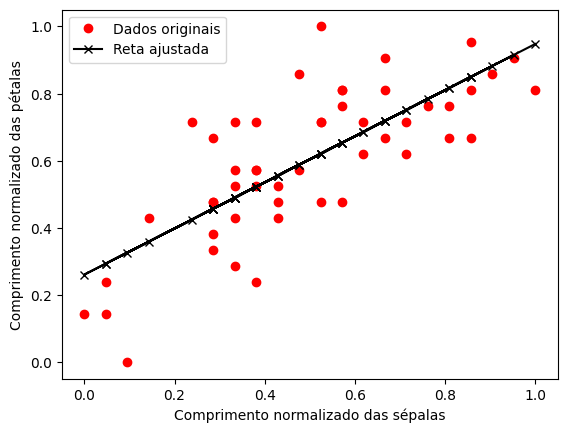

In [ ]:
y_pred = model.forward(x_train_bias)
plt.plot(x_train, y_train, 'ro', label='Dados originais')
plt.plot(x_train, y_pred, 'kx-', label='Reta ajustada')
plt.xlabel('Comprimento normalizado das sépalas')
plt.ylabel('Comprimento normalizado das pétalas')
plt.legend()
plt.show()

In [ ]:
model.w

array([[0.26135426, 0.68644528]])

### Parâmetros treinados

In [ ]:
print(model.w)   # [w0 w1]

[[0.26135426 0.68644528]]


### Custo do modelo treinado

In [ ]:
y_chapeu = model.forward(x_train_bias)
J = loss = np.square(y_chapeu - y_train).mean()
print(J)

0.021169424154941465


In [ ]:
loss = np.square(y_pred - y_train).mean()
loss

np.float64(0.021169424154941465)

### Valor ótimo: solução analítica

A regressão linear tem solução exata, dada pela equação normal (o ponto em que $\nabla_{\mathbf{w}} J = 0$):

$$ \mathbf{w}^T = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y} $$

com shapes $(2, 1) = (2, 2) \times (2, M) \times (M, 1)$. O gradiente descendente deve chegar perto desse valor.

In [ ]:
x = x_train_bias
y = y_train
w_opt = (np.linalg.inv((x.T).dot(x)).dot(x.T)).dot(y)   # (2, 1)
print(w_opt.T)

[[0.26134159 0.68646976]]


In [ ]:
model.w

array([[0.26135426, 0.68644528]])

## Exercícios

### Questões

1. Quantos parâmetros são treinados nesse modelo?

R.: 2 - > w0 e w1

2. Qual é o número de atributos de entrada para a rede?

R.: x tem 50 elementos. Numero de atributos de entrada é 2 (bias, x)

3. Qual é o número de saídas da rede?

R.: 1, y_chapeu = ypred

4. Suponha que agora você tenha 5 mil amostras para fazer a predição. Qual é o shape da matriz de entrada? Qual é o shape da matriz de saída?

R.: Entrada: (5000, 2)
    Saída: (5000, 1)

### Atividades

1. Modifique o laço de treinamento via gradiente descendente para guardar numa lista `losses` o valor do custo no final de cada época. Após o treinamento, plote o custo em função da época.

In [ ]:
model = Net(2, 1)

historico_mse = []

n_epochs = 200
learning_rate = 0.5

for epoca in range(n_epochs):

    # predição
    y_pred = model.forward(x_train_bias)

    # cálculo do erro (MSE)
    mse = np.mean((y_pred - y_train) ** 2)

    # salva o erro da época
    historico_mse.append(mse)

    # cálculo do gradiente
    grad = (2 / n_samples) * (x_train_bias.T @ (y_pred - y_train))

    # atualização dos pesos
    model.w = model.w - learning_rate * grad.T

    # exibição do progresso
    if (epoca + 1) % 10 == 0:
        print(f"Época {epoca + 1}/{n_epochs} - MSE: {mse:.6f}")

Época 10/200 - MSE: 0.027830
Época 20/200 - MSE: 0.023704
Época 30/200 - MSE: 0.022134
Época 40/200 - MSE: 0.021536
Época 50/200 - MSE: 0.021309
Época 60/200 - MSE: 0.021223
Época 70/200 - MSE: 0.021190
Época 80/200 - MSE: 0.021177
Época 90/200 - MSE: 0.021172
Época 100/200 - MSE: 0.021171
Época 110/200 - MSE: 0.021170
Época 120/200 - MSE: 0.021170
Época 130/200 - MSE: 0.021169
Época 140/200 - MSE: 0.021169
Época 150/200 - MSE: 0.021169
Época 160/200 - MSE: 0.021169
Época 170/200 - MSE: 0.021169
Época 180/200 - MSE: 0.021169
Época 190/200 - MSE: 0.021169
Época 200/200 - MSE: 0.021169


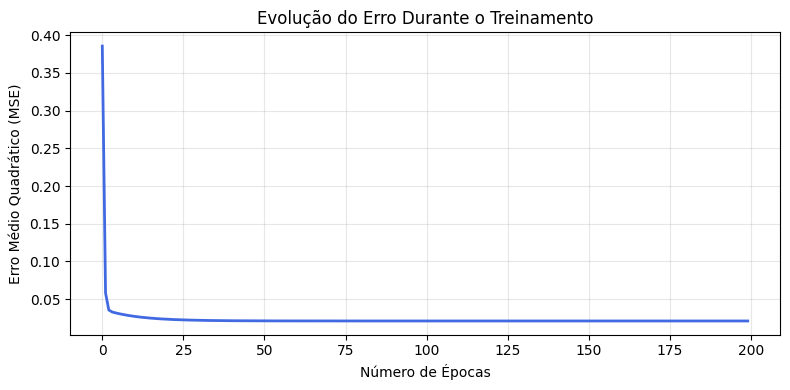

In [ ]:
plt.figure(figsize=(8, 4))

plt.plot(historico_mse, color="royalblue", linewidth=2)

plt.title("Evolução do Erro Durante o Treinamento")
plt.xlabel("Número de Épocas")
plt.ylabel("Erro Médio Quadrático (MSE)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

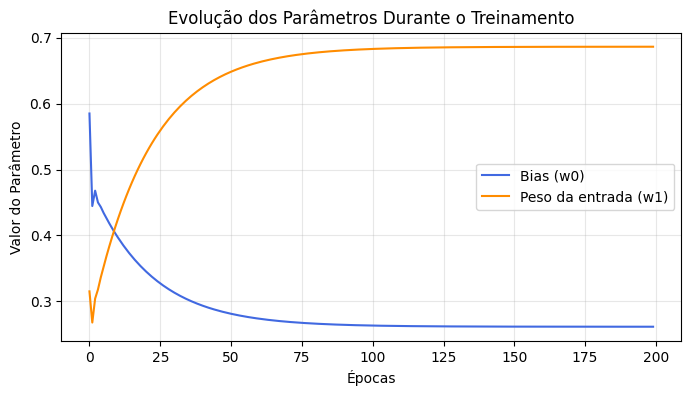

In [ ]:
# organiza os pesos ao longo do treinamento
pesos_array = np.array(weights).squeeze()

bias = pesos_array[:, 0]
peso_entrada = pesos_array[:, 1]

plt.figure(figsize=(8, 4))

plt.plot(bias, label='Bias (w0)', color='royalblue')
plt.plot(peso_entrada, label='Peso da entrada (w1)', color='darkorange')

plt.title('Evolução dos Parâmetros Durante o Treinamento')
plt.xlabel('Épocas')
plt.ylabel('Valor do Parâmetro')

plt.legend()
plt.grid(alpha=0.3)

plt.show()

2. Calcule o valor do custo (MSE) da rede com os parâmetros inicializados, sem treinamento.

In [ ]:
# cria uma nova rede com pesos aleatórios
rede_inicial = Net(2, 1)

# realiza a predição sem treinamento
saida_inicial = rede_inicial.forward(x_train_bias)

# calcula o erro médio quadrático
mse_inicial = np.mean((saida_inicial - y_train) ** 2)

print(f"MSE antes do treinamento: {mse_inicial:.6f}")

MSE antes do treinamento: 0.336324


3. Coloque os valores dos pesos da solução analítica no modelo da rede, calcule o valor do custo (MSE) e compare com o custo obtido pelo gradiente descendente.

In [ ]:
# --- Questão 3: Solução Analítica ---
# Fórmula: w = (X^T X)^-1 X^T y
w_analitico = np.linalg.inv(x_train_bias.T @ x_train_bias) @ x_train_bias.T @ y_train

# Colocando no modelo e calculando o custo (MSE)
model.w = w_analitico.T
y_pred_analitico = model.forward(x_train_bias)
loss_analitico = np.square(y_pred_analitico - y_train).mean()

# Comparação
print(f"Pesos Gradiente Descendente: {model.w}")
print(f"Pesos Solução Analítica:     {w_analitico.T}")
print(f"Custo (MSE) Gradiente:       {loss:.6f}")
print(f"Custo (MSE) Analítico:       {loss_analitico:.6f}")

Pesos Gradiente Descendente: [[0.26134159 0.68646976]]
Pesos Solução Analítica:     [[0.26134159 0.68646976]]
Custo (MSE) Gradiente:       0.021169
Custo (MSE) Analítico:       0.021169


In [ ]:
model.w

array([[0.26134159, 0.68646976]])

In [ ]:
x = x_train_bias
y = y_train
w_opt = (np.linalg.inv((x.T).dot(x)).dot(x.T)).dot(y)   # (2, 1)
print(w_opt.T)

[[0.26134159 0.68646976]]


In [ ]:
model.w = w_opt.T
model.w
y_pred_analistico = model.forward(x_train_bias)
loss_analitica = np.square(y_pred_analistico - y_train).mean()
print("Custo com w ótimo analítico: " + str(loss_analitica))
print("Custo com gradiente:         " + str(loss))

Custo com w ótimo analítico: 0.021169424119097165
Custo com gradiente:         0.021169424163745315


*Escreva sua resposta aqui.*

## Aprendizados

- A predição de todas as amostras é um produto de matrizes, $\hat{\mathbf{y}} = \mathbf{X}\mathbf{w}^T$, com shapes $(M, 1) = (M, 2) \times (2, 1)$; a coluna de 1s em `x_train_bias` transforma o bias num peso comum.
- O gradiente do MSE é $\nabla_{\mathbf{w}} J = \frac{2}{M}\mathbf{X}^T(\mathbf{X}\mathbf{w}^T - \mathbf{y})$, e cada época faz predição → custo → gradiente → atualização.
- O gradiente descendente chega perto da solução analítica (equação normal) sem inverter nenhuma matriz; isso é o que permite treinar modelos em que não existe solução exata.
- O laço deste notebook é o mesmo que o PyTorch executará nos próximos notebooks: no 2.3 com tensores, no 2.4 com o gradiente calculado automaticamente.